LAB05

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show_images(images, titles, cmap='gray', figsize=(14, 6)):
    n = len(images)
    plt.figure(figsize=figsize)
    for i in range(n):
        plt.subplot(1, n, i + 1)
        if len(images[i].shape) == 2:
            plt.imshow(images[i], cmap=cmap)
        else:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

#16 Bài tập cuối bài


##16.1 Bài tập 1. Làm sạch biên tế bào có gai nhỏ

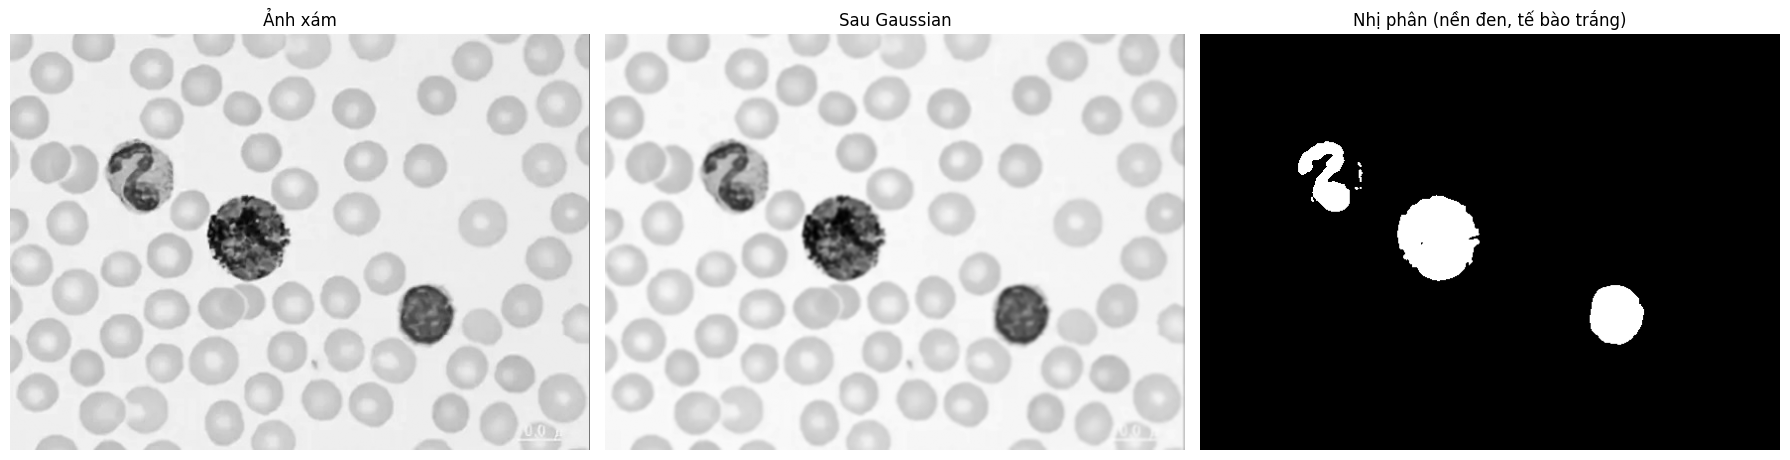

In [ ]:

img = cv2.imread("/content/WBC1.jpg", cv2.IMREAD_GRAYSCALE)
blur = cv2.GaussianBlur(img, (5, 5), 0)
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

show_images([img, blur, binary], ["Ảnh xám", "Sau Gaussian", "Nhị phân (nền đen, tế bào trắng)"], figsize=(18, 6))

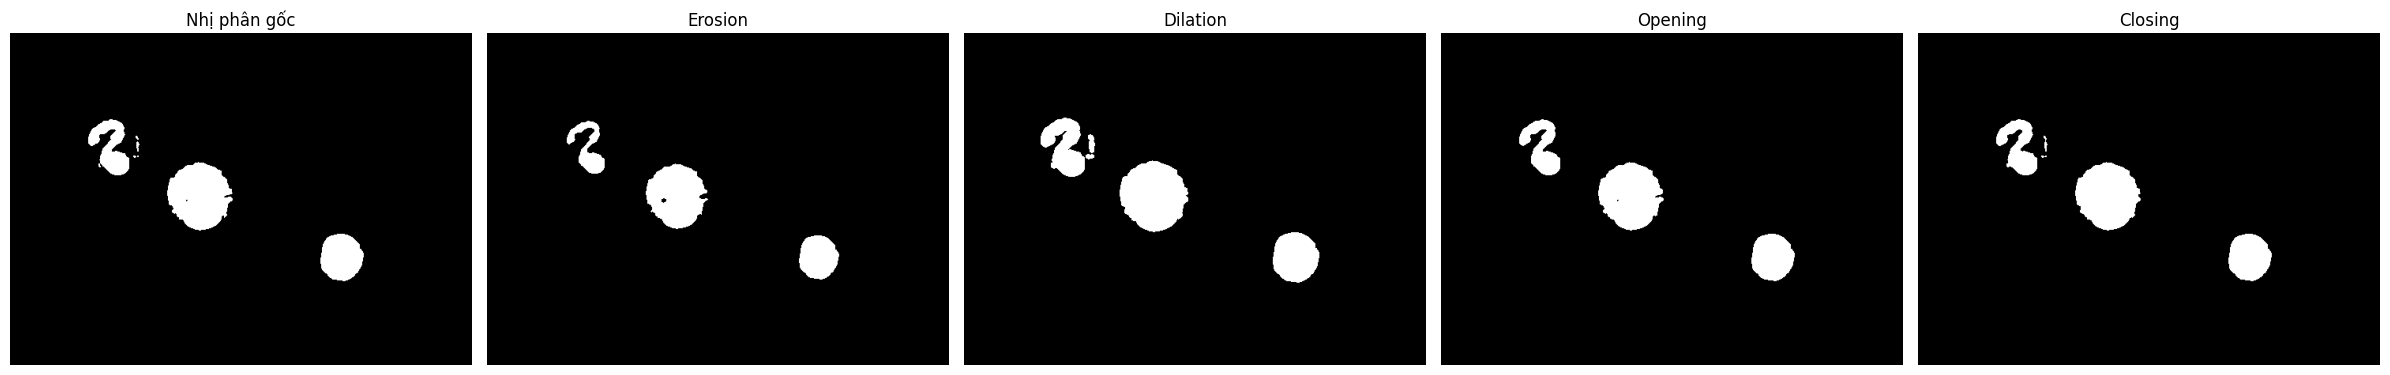

In [ ]:
# Áp dụng riêng từng phép erosion, dilation, opening, closing với cùng kernel ellipse 5x5
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

show_images(
    [binary, erosion, dilation, opening, closing],
    ["Nhị phân gốc", "Erosion", "Dilation", "Opening", "Closing"],
    figsize=(24, 5)
)

In [ ]:
# Đo diện tích, số đối tượng và tổng chu vi biên của từng kết quả để so sánh độ mượt và mức giữ hình dạng
def do_dac_trung(anh):
    dien_tich = cv2.countNonZero(anh)
    contours, _ = cv2.findContours(anh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    so_doi_tuong = len(contours)
    chu_vi = sum(cv2.arcLength(c, True) for c in contours)
    return dien_tich, so_doi_tuong, chu_vi

danh_sach = [("Nhị phân gốc", binary), ("Erosion", erosion), ("Dilation", dilation),
             ("Opening", opening), ("Closing", closing)]

area_goc = cv2.countNonZero(binary)
print(f"{'Phép':<14}{'Diện tích':>12}{'Thay đổi':>12}{'Số đối tượng':>15}{'Tổng chu vi':>14}")
for ten, anh in danh_sach:
    dt, n, cv_ = do_dac_trung(anh)
    thay_doi = (dt - area_goc) / area_goc * 100
    print(f"{ten:<14}{dt:>12}{thay_doi:>11.1f}%{n:>15}{cv_:>14.0f}")

Phép             Diện tích    Thay đổi   Số đối tượng   Tổng chu vi
Nhị phân gốc          9804        0.0%              7           867
Erosion               8178      -16.6%              3           751
Dilation             11576       18.1%              5           905
Opening               9706       -1.0%              3           792
Closing               9870        0.7%              5           840


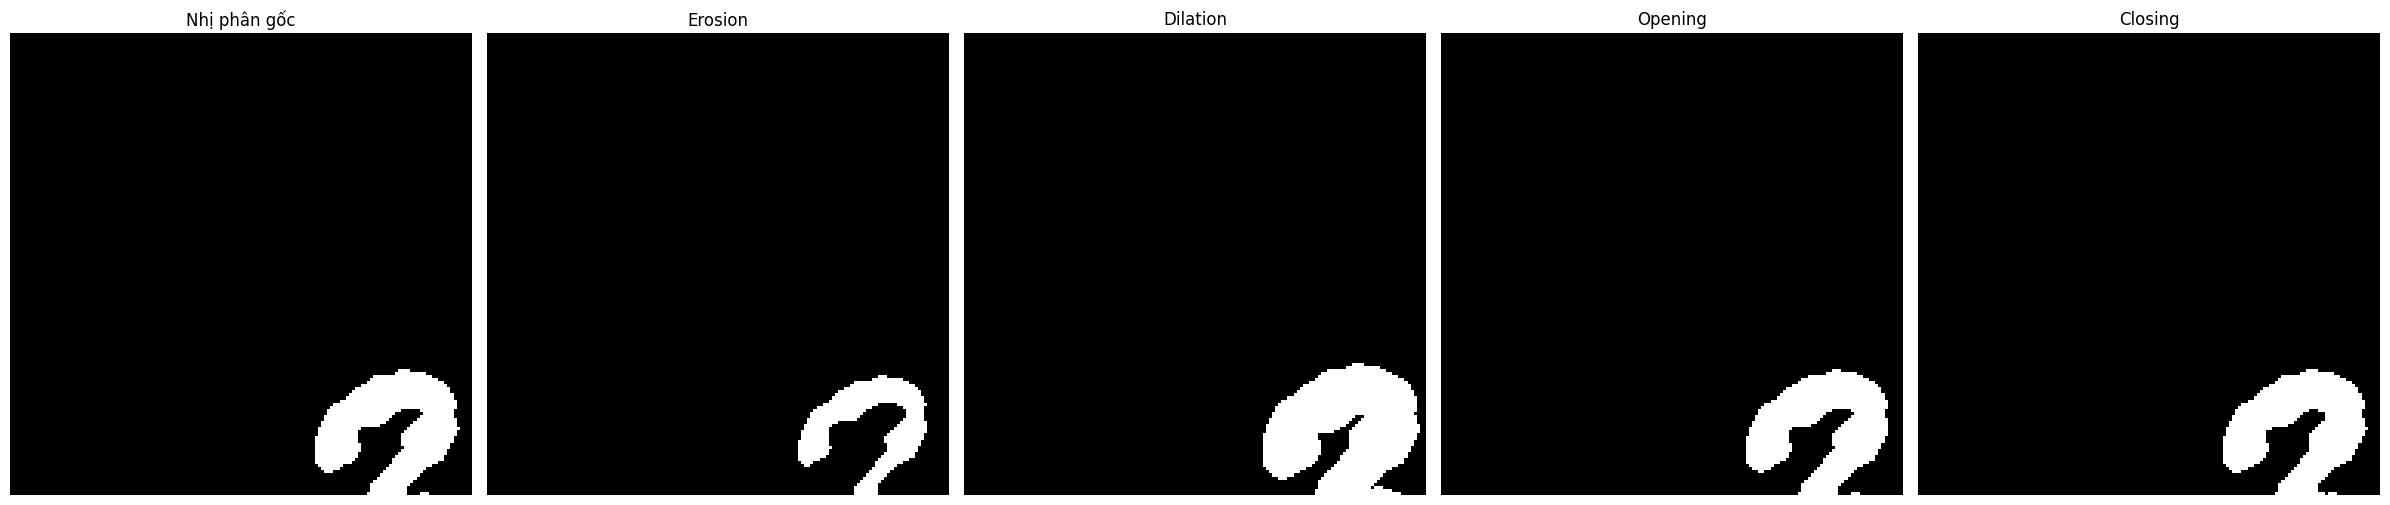

In [ ]:
# Phóng to một vùng của ảnh để nhìn rõ biên và các gai nhỏ trước và sau xử lý (đổi y1, y2, x1, x2 để chọn vùng khác)
y1, y2, x1, x2 = 0, 150, 0, 150

vung = [anh[y1:y2, x1:x2] for _, anh in danh_sach]
tieu_de = [ten for ten, _ in danh_sach]
show_images(vung, tieu_de, figsize=(24, 5))

Nhận xét và kết luận: làm sạch gai nhỏ ở biên (ảnh WBC, kernel ellipse 5x5)

**1. Bảng kết quả**

| Phép | Diện tích | Thay đổi | Số đối tượng | Tổng chu vi |
|---|---|---|---|---|
| Nhị phân gốc | 9804 | 0.0% | 7 | 867 |
| Erosion | 8178 | -16.6% | 3 | 751 |
| Dilation | 11576 | +18.1% | 5 | 905 |
| Opening | 9706 | -1.0% | 3 | 792 |
| Closing | 9870 | +0.7% | 5 | 840 |

**2. So sánh**
- **Độ mượt của biên:** ảnh gốc có 7 đối tượng, trong đó ba là tế bào và các vùng còn lại là chấm nhiễu nhỏ. Erosion và Opening đưa số đối tượng về 3, tức là loại bỏ các chấm nhiễu, đồng thời giảm tổng chu vi (751 và 792 so với 867). Dilation và Closing vẫn còn 5 đối tượng, chu vi của Dilation còn tăng lên (905), nghĩa là chấm nhiễu không bị loại mà còn dính hoặc to ra.
- **Mức giữ hình dạng tổng thể:** Opening giữ diện tích gần như nguyên (-1.0%) và Closing cũng gần như nguyên (+0.7%). Erosion làm diện tích giảm 16.6%, còn Dilation làm tăng 18.1%, nên hai phép này làm sai kích thước thật của tế bào.
- **Nguy cơ mất chi tiết thật:** Erosion có nguy cơ cao nhất vì co cả thân tế bào, các phần mảnh bị mỏng đi. Opening có nguy cơ thấp nếu kernel nhỏ hơn cấu trúc thật. Dilation làm gai và nhiễu dính vào tế bào. Closing không loại được gai.

**3. Kết luận**
Phép phù hợp nhất để khử gai nhỏ ở rìa là **Opening**. Opening loại được các chấm nhiễu và gai nhỏ (số đối tượng giảm từ 7 xuống 3, chu vi giảm từ 867 xuống 792) mà diện tích gần như không đổi (-1.0%). Erosion cũng loại được nhiễu nhưng làm tế bào co nhỏ, diện tích giảm tới 16.6%. Lý do là Opening = Erosion rồi Dilation: bước co bỏ chi tiết nhỏ, bước giãn khôi phục lại gần đúng kích thước chính. Dilation và Closing không phù hợp vì chúng mở rộng hoặc lấp vùng trắng chứ không loại bỏ phần nhô ra.

##16.2 Bài tập 2. Lấp lỗ nhỏ trong vùng tổn thương